In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv("/content/ML_Lab_Multiple_Linear_Regression_House_Prices.csv")

In [ ]:
df

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_Metro_km,Parking,Floor,Balconies,Price_Lakhs
0,1726,2,2,0,14.1,1,10,3,168.54
1,2059,2,1,4,9.8,1,10,3,185.35
2,1460,4,4,15,8.0,1,0,3,183.25
3,1894,4,4,18,10.0,0,0,0,187.83
4,1730,1,1,3,6.8,1,1,2,158.35
...,...,...,...,...,...,...,...,...,...
95,2100,1,1,0,8.5,1,6,3,189.97
96,1302,5,5,14,3.6,1,10,1,187.44
97,1001,1,1,1,14.2,1,5,2,126.92
98,1329,3,3,15,11.8,1,7,0,139.06


In [ ]:
df.head()

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_Metro_km,Parking,Floor,Balconies,Price_Lakhs
0,1726,2,2,0,14.1,1,10,3,168.54
1,2059,2,1,4,9.8,1,10,3,185.35
2,1460,4,4,15,8.0,1,0,3,183.25
3,1894,4,4,18,10.0,0,0,0,187.83
4,1730,1,1,3,6.8,1,1,2,158.35


In [ ]:
print(df.describe())

         Area_sqft    Bedrooms   Bathrooms   Age_years  Distance_to_Metro_km  \
count   100.000000  100.000000  100.000000  100.000000            100.000000   
mean   1572.580000    2.970000    2.780000    9.940000              7.807000   
std     532.161652    1.473366    1.467355    6.499137              4.130602   
min     613.000000    1.000000    1.000000    0.000000              0.700000   
25%    1149.000000    1.750000    1.000000    4.000000              4.300000   
50%    1598.000000    3.000000    3.000000   10.500000              8.250000   
75%    2019.000000    4.000000    4.000000   16.000000             10.650000   
max    2499.000000    5.000000    5.000000   20.000000             14.700000   

          Parking      Floor   Balconies  Price_Lakhs  
count  100.000000  100.00000  100.000000   100.000000  
mean     0.720000    4.44000    1.400000   162.241500  
std      0.451261    3.27932    1.073087    42.890963  
min      0.000000    0.00000    0.000000    53.000000  

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Area_sqft             100 non-null    int64  
 1   Bedrooms              100 non-null    int64  
 2   Bathrooms             100 non-null    int64  
 3   Age_years             100 non-null    int64  
 4   Distance_to_Metro_km  100 non-null    float64
 5   Parking               100 non-null    int64  
 6   Floor                 100 non-null    int64  
 7   Balconies             100 non-null    int64  
 8   Price_Lakhs           100 non-null    float64
dtypes: float64(2), int64(7)
memory usage: 7.2 KB


In [ ]:
df.isnull().sum()

,0
Area_sqft,0
Bedrooms,0
Bathrooms,0
Age_years,0
Distance_to_Metro_km,0
Parking,0
Floor,0
Balconies,0
Price_Lakhs,0


In [ ]:
features = [
    'Area_sqft',
    'Bedrooms',
    'Bathrooms',
    'Age_years',
    'Distance_to_Metro_km',
    'Parking',
    'Floor',
    'Balconies',
    'Price_Lakhs'
]

x = df[features].values

y = df['Price_Lakhs'].values

In [ ]:
print(df[features].describe())

         Area_sqft    Bedrooms   Bathrooms   Age_years  Distance_to_Metro_km  \
count   100.000000  100.000000  100.000000  100.000000            100.000000   
mean   1572.580000    2.970000    2.780000    9.940000              7.807000   
std     532.161652    1.473366    1.467355    6.499137              4.130602   
min     613.000000    1.000000    1.000000    0.000000              0.700000   
25%    1149.000000    1.750000    1.000000    4.000000              4.300000   
50%    1598.000000    3.000000    3.000000   10.500000              8.250000   
75%    2019.000000    4.000000    4.000000   16.000000             10.650000   
max    2499.000000    5.000000    5.000000   20.000000             14.700000   

          Parking      Floor   Balconies  Price_Lakhs  
count  100.000000  100.00000  100.000000   100.000000  
mean     0.720000    4.44000    1.400000   162.241500  
std      0.451261    3.27932    1.073087    42.890963  
min      0.000000    0.00000    0.000000    53.000000  

In [ ]:
m = len(y)

weights = np.zeros(x.shape[1])
bias = 0
learning_rate = 0.0000001
iterations = 1000

print(m)
print("\nWeights: ", weights)

100

Weights:  [0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
cost_history = []

for i in range(iterations):
  #Prediction
  y_pred = x @ weights + bias
  #Error
  error = y_pred - y
  #Individual Loss
  individual_loss = 0.5 * (error ** 2)

  #Cost
  cost = np.mean(individual_loss)

  #Store cost
  cost_history.append(cost)

  #Gradients
  dw = (1/m) * (x.T @ error)

  db = (1/m) * np.sum(error)


  # Parameter update
  weights = weights - learning_rate * dw

  bias = bias - learning_rate * db

In [ ]:
y_pred

array([171.14789151, 202.50988175, 148.97746293, 188.08217244,
       170.37785875, 174.82302931, 232.37359865, 159.96041997,
       226.52594377,  75.224554  , 103.4643183 , 184.65438698,
        96.99991167, 206.27150894,  75.24916641, 197.32756191,
       172.55045511, 148.72988197, 222.73601297,  73.74620937,
       221.46972121, 187.3106502 , 140.76451743,  94.81791251,
       207.04538395, 199.70640596, 142.35888615,  98.43155093,
       176.5467606 , 155.35914296,  91.06874137, 175.03776124,
       105.19599367, 189.61780396,  63.03230607,  85.87366894,
       136.71870471, 145.67343989, 211.86236886, 109.94107207,
       165.36218179, 112.30534697, 229.89514219, 205.46728148,
       127.04714214, 156.19909186, 241.86110242,  81.4014907 ,
       151.66007034, 133.04135342, 152.99442853, 116.73558271,
       244.17846224, 214.20589789, 184.71453076, 142.78632478,
       213.72521078, 177.39660034, 202.93413676, 240.22536352,
       127.13204656,  66.09287911, 147.35929189,  80.82

In [ ]:
error

array([  2.60789151,  17.15988175, -34.27253707,   0.25217244,
        12.02785875, -55.80697069, -13.85640135,  28.65041997,
       -37.10405623, -30.915446  ,  21.2143183 , -18.71561302,
       -39.99008833,   4.21150894, -59.94083359,   7.41756191,
       -12.33954489, -22.15011803,  37.71601297, -10.70379063,
        47.09972121,  39.8306502 , -41.49548257,  -9.68208749,
        25.97538395,  22.08640596, -24.50111385,  -4.84844907,
        31.9467606 ,  -7.78085704, -34.64125863,  18.16776124,
         0.37599367,  23.52780396, -10.65769393, -10.49633106,
       -25.00129529,  -8.92656011,  43.22236886, -27.84892793,
        14.79218179, -17.42465303,  -8.49485781,  25.99728148,
        17.00714214,   1.85909186, -25.54889758, -25.6385093 ,
        26.01007034, -46.32864658,  14.29442853, -11.20441729,
        34.37846224,  28.12589789,   6.36453076,  -5.48367522,
       -20.58478922, -27.80339966,  55.14413676,  19.83536352,
       -28.68795344, -38.61712089, -37.49070811, -40.12

In [ ]:
individual_loss

array([3.40054908e+00, 1.47230771e+02, 5.87303398e+02, 3.17954708e-02,
       7.23346931e+01, 1.55720899e+03, 9.59999291e+01, 4.10423282e+02,
       6.88355494e+02, 4.77882401e+02, 2.25023651e+02, 1.75137085e+02,
       7.99603582e+02, 8.86840380e+00, 1.79645177e+03, 2.75101123e+01,
       7.61321841e+01, 2.45313864e+02, 7.11248817e+02, 5.72855669e+01,
       1.10919187e+03, 7.93240348e+02, 8.60937537e+02, 4.68714091e+01,
       3.37360286e+02, 2.43904664e+02, 3.00152290e+02, 1.17537292e+01,
       5.10297756e+02, 3.02708681e+01, 6.00008400e+02, 1.65033774e+02,
       7.06856204e-02, 2.76778780e+02, 5.67932200e+01, 5.50864829e+01,
       3.12532383e+02, 3.98417377e+01, 9.34086585e+02, 3.87781393e+02,
       1.09404321e+02, 1.51809267e+02, 3.60813046e+01, 3.37929322e+02,
       1.44621442e+02, 1.72811127e+00, 3.26373084e+02, 3.28666580e+02,
       3.38261880e+02, 1.07317175e+03, 1.02165343e+02, 6.27694834e+01,
       5.90939333e+02, 3.95533066e+02, 2.02536259e+01, 1.50353470e+01,
      

In [ ]:
cost

np.float64(402.8535189913398)

In [ ]:
print("\n Weights: ", dw)
print("\nBias: ", db)


 Weights:  [  88.92494057  -48.45856523  -47.6498442   -12.6774252   -26.13292212
   -4.81053385  -43.3826898   -13.37291707 -890.7059196 ]

Bias:  -5.419646488563781


In [ ]:
print("Weights: ", weights)
print("\n Bias: ", bias)


Weights:  [0.08898691 0.00525767 0.00516146 0.00190736 0.00318929 0.00054627
 0.00481073 0.00148246 0.10345741]

 Bias:  0.0006265420199386098


In [ ]:
print("Final Cost:", cost_history[-1])

Final Cost: 402.8535189913398


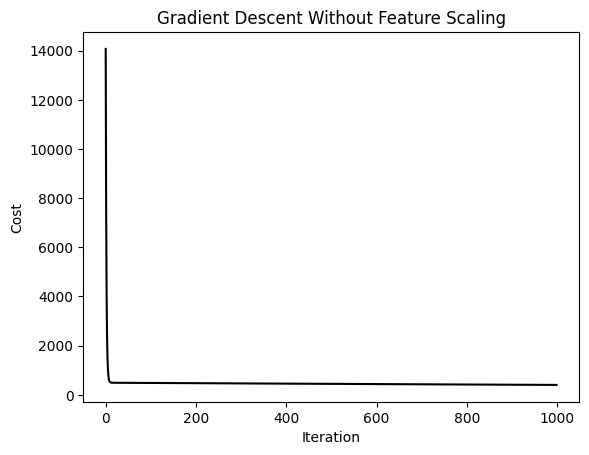

In [ ]:
plt.plot(cost_history, color = "black")

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.title("Gradient Descent Without Feature Scaling")

plt.show()

In [ ]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
print(x_scaled[:5])

[[ 0.28974824 -0.66167301 -0.53424658 -1.53713872  1.53118203  0.62360956
   1.70401496  1.4985373   0.14758891]
 [ 0.91865036 -0.66167301 -1.21917808 -0.91857183  0.48492703  0.62360956
   1.70401496  1.4985373   0.54148741]
 [-0.21261802  0.70260124  0.83561644  0.78248712  0.04695982  0.62360956
  -1.36076014  1.4985373   0.49227939]
 [ 0.60703219  0.70260124  0.83561644  1.24641229  0.53359005 -1.60356745
  -1.36076014 -1.31122014  0.59959974]
 [ 0.29730262 -1.34381014 -1.21917808 -1.07321356 -0.24501832  0.62360956
  -1.05428263  0.56195149 -0.09118715]]


In [ ]:
weights = np.zeros(x_scaled.shape[1])
bias = 0
print("Weights: ", weights)

learning_rate = 0.01
iterations = 1000

Weights:  [0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
cost_history_scaled = []
for i in range(iterations):
  #Prediction
  y_pred = x_scaled @ weights + bias
  #Error
  error = y_pred - y
  #Individual Loss
  individual_loss = 0.5 * (error ** 2)
  #Cost
  cost = np.mean(individual_loss)
  #Store cost
  cost_history_scaled.append(cost)
  #Gradients
  dw = (1/m) * (x_scaled.T @ error)
  db = (1/m) * np.sum(error)
  # Parameter update
  weights = weights - learning_rate * dw
  bias = bias - learning_rate * db

In [ ]:
y_pred

array([171.61300363, 189.21203599, 177.47753105, 185.44222185,
       157.40650869, 227.01064473, 247.14371461, 133.65864476,
       259.52325078, 100.65595338,  83.35468661, 204.5895026 ,
       138.92454859, 208.26590184, 132.2819654 , 180.98672266,
       190.2115636 , 169.3918253 , 187.87069802,  82.84029147,
       176.50417216, 150.19213088, 180.24576043, 107.66135491,
       181.19203295, 176.67935317, 165.10016696, 107.07404054,
       146.03348241, 160.19763074, 123.60543162, 160.8867436 ,
       102.54977778, 162.94811752,  79.56191087,  91.55228639,
       164.94393976, 151.48366   , 171.71954982, 144.48321872,
       157.82186265, 129.41894084, 238.97994578, 185.22035211,
       105.31044719, 159.37304087, 270.47182016, 109.35700348,
       126.07149255, 178.20920221, 140.59480012, 127.67108284,
       206.52239693, 188.09059034, 174.17003471, 152.94809786,
       233.29713651, 199.31961514, 157.2843106 , 224.09257871,
       155.53636064, 103.47944645, 184.52635727, 122.92

In [ ]:
print("\n Weights: ", dw)
print("\n Bias: ", db)


 Weights:  [ 0.44854627  0.13782967  0.09389147 -0.07529529 -0.04249759  0.03668224
  0.03547376  0.02477324 -0.44487646]

 Bias:  -0.007074917107898813


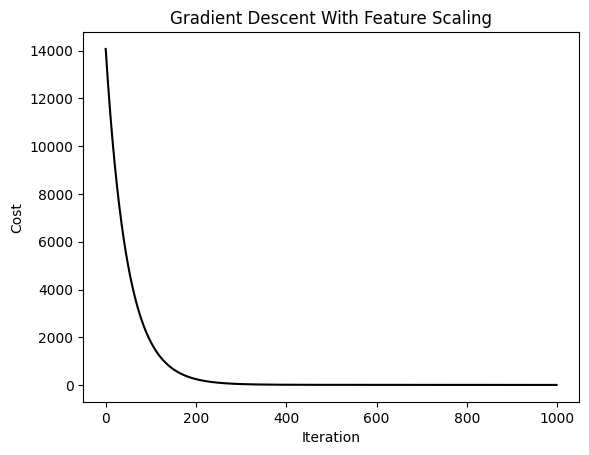

In [ ]:
plt.plot(cost_history_scaled, color = "black")

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.title("Gradient Descent With Feature Scaling")

plt.show()

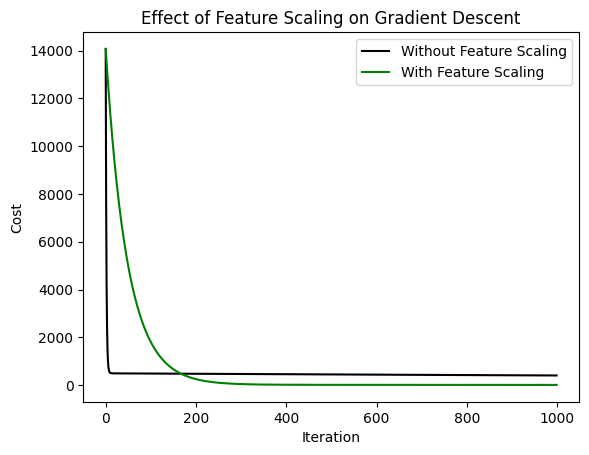

In [ ]:
plt.plot(cost_history, color = "black", label = "Without Feature Scaling")
plt.plot(cost_history_scaled, color = "green", label = "With Feature Scaling")

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.title("Effect of Feature Scaling on Gradient Descent")

plt.legend()
plt.show()